<a href="https://colab.research.google.com/github/FikarBahrul/PCVK_Ganjil_2026/blob/main/Week07.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<a href="https://colab.research.google.com/github/bavucadoz/PCVK-Ganjil-2026/blob/main/Week07.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
NAMA = 'Fikar Bahrul Santoso'
NIM = '244107020160'
KELAS = 'TI-3E/08'
print('NAMA :', NAMA)
print('NIM  :', NIM)
print('KELAS:', KELAS)

NAMA : Fikar Bahrul Santoso
NIM  : 244107020160
KELAS: TI-3E/08


# **D. Tugas Praktikum**

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

In [ ]:
import cv2 as cv
from google.colab.patches import cv2_imshow
import numpy as np
import math
import pandas as pd
import matplotlib.pyplot as plt
from collections import deque
from skimage import data
from sklearn.cluster import KMeans

**Percobaan 1 - Memuat Citra dan Konversi Grayscale**

In [ ]:
base = '/content/drive/MyDrive/Semester 5/PCVK/Week07/Images/'

# Percobaan 1 - Memuat citra dan mengubahnya menjadi citra grayscale

img_bgr = cv.imread(base + 'lena_gs_lc2.jpg')
gray = cv.cvtColor(img_bgr, cv.COLOR_BGR2GRAY)

plt.figure(figsize=(10, 5))
plt.subplot(1, 2, 1)
plt.imshow(cv.cvtColor(img_bgr, cv.COLOR_BGR2RGB))
plt.title('Citra Asli')
plt.axis('off')
plt.subplot(1, 2, 2)
plt.imshow(gray, cmap='gray')
plt.title('Citra Grayscale')
plt.axis('off')
plt.tight_layout()
plt.show()

**Percobaan 2 - Menampilkan Histogram Citra**

In [ ]:
# Percobaan 2 - Menampilkan histogram citra grayscale
# Histogram dipakai untuk melihat distribusi intensitas, sehingga nilai ambang lebih mudah ditentukan

plt.figure(figsize=(10, 4))
plt.hist(gray.ravel(), bins=256, range=(0, 256), color='gray')
plt.title('Histogram Citra Grayscale')
plt.xlabel('Intensitas')
plt.ylabel('Jumlah Piksel')
plt.tight_layout()
plt.show()

**Percobaan 3 - Global Thresholding (BINARY, BINARY_INV, TRUNC, TOZERO, TOZERO_INV)**

In [ ]:
# Percobaan 3 - Global Thresholding (BINARY, BINARY_INV, TRUNC, TOZERO, TOZERO_INV)
# Citra gradien dibuat dengan np.linspace sesuai jobsheet, threshold = 200

gradient_row = np.linspace(0, 255, 255, dtype=np.uint8)
img = np.tile(gradient_row, (255, 1))

thresh = 200
maxval = 255

thresh1 = np.where(img > thresh, maxval, 0).astype(np.uint8)     # BINARY
thresh2 = np.where(img > thresh, 0, maxval).astype(np.uint8)     # BINARY_INV
thresh3 = np.where(img > thresh, thresh, img).astype(np.uint8)   # TRUNC
thresh4 = np.where(img > thresh, img, 0).astype(np.uint8)        # TOZERO
thresh5 = np.where(img > thresh, 0, img).astype(np.uint8)        # TOZERO_INV

titles = ['Citra Original', 'BINARY', 'BINARY_INV', 'TRUNC', 'TOZERO', 'TOZERO_INV']
images = [img, thresh1, thresh2, thresh3, thresh4, thresh5]

plt.figure(figsize=(15, 5))
for i in range(len(images)):
    plt.subplot(2, 3, i + 1)
    plt.imshow(images[i], cmap='gray', vmin=0, vmax=255)
    plt.title(titles[i])
    plt.xticks([]), plt.yticks([])
plt.tight_layout()
plt.show()

**Percobaan 4 - Adaptive Thresholding (Mean & Gaussian) Manual**

In [ ]:
# Percobaan 4 - Adaptive Threshold (Adaptive Mean & Adaptive Gaussian) secara manual
# Tidak memakai cv.threshold(), cv.adaptiveThreshold(), maupun fungsi filter bawaan

filename = base + 'sudoku-original.jpg'
img_bgr = cv.imread(filename)
gray = np.dot(img_bgr[..., :3], [0.114, 0.587, 0.299]).astype(np.uint8)

# Global Thresholding manual sebagai pembanding (T = 127)
thresh_val = 127
th1 = np.where(gray > thresh_val, 255, 0).astype(np.uint8)

block_size = 11
C = 2
sigma = 2
pad = block_size // 2
padded_gray = np.pad(gray, pad, mode='reflect')

x, y = np.meshgrid(np.arange(-pad, pad + 1), np.arange(-pad, pad + 1))
gaussian_kernel = np.exp(-(x**2 + y**2) / (2 * sigma**2))
gaussian_kernel /= gaussian_kernel.sum()

height, width = gray.shape
th2 = np.zeros((height, width), dtype=np.uint8)  # Adaptive Mean
th3 = np.zeros((height, width), dtype=np.uint8)  # Adaptive Gaussian

for i in range(height):
    for j in range(width):
        window = padded_gray[i:i + block_size, j:j + block_size]
        mean_val = np.mean(window)
        T_mean = mean_val - C
        th2[i, j] = 255 if gray[i, j] > T_mean else 0

        gauss_val = np.sum(window * gaussian_kernel)
        T_gauss = gauss_val - C
        th3[i, j] = 255 if gray[i, j] > T_gauss else 0

titles = ['Citra Asli', 'Global Thresholding (T = 127)', 'Adaptive Mean (Manual)', 'Adaptive Gaussian (Manual)']
citra2 = [gray, th1, th2, th3]

plt.figure(figsize=(18, 5))
for i in range(len(citra2)):
    plt.subplot(1, 4, i + 1)
    plt.imshow(citra2[i], cmap='gray', vmin=0, vmax=255)
    plt.title(titles[i], fontsize=11)
    plt.xticks([]), plt.yticks([])
plt.tight_layout()
plt.show()

**Percobaan 5A - Otsu Thresholding Manual**

/tmp/ipykernel_712/2397856391.py:22: RuntimeWarning: invalid value encountered in divide
  mub = np.sum(intensity_arr[:t] * his[:t]) / float(pcb)
/tmp/ipykernel_712/2397856391.py:23: RuntimeWarning: invalid value encountered in divide
  muf = np.sum(intensity_arr[t:] * his[t:]) / float(pcf)


Nilai threshold Otsu : 93


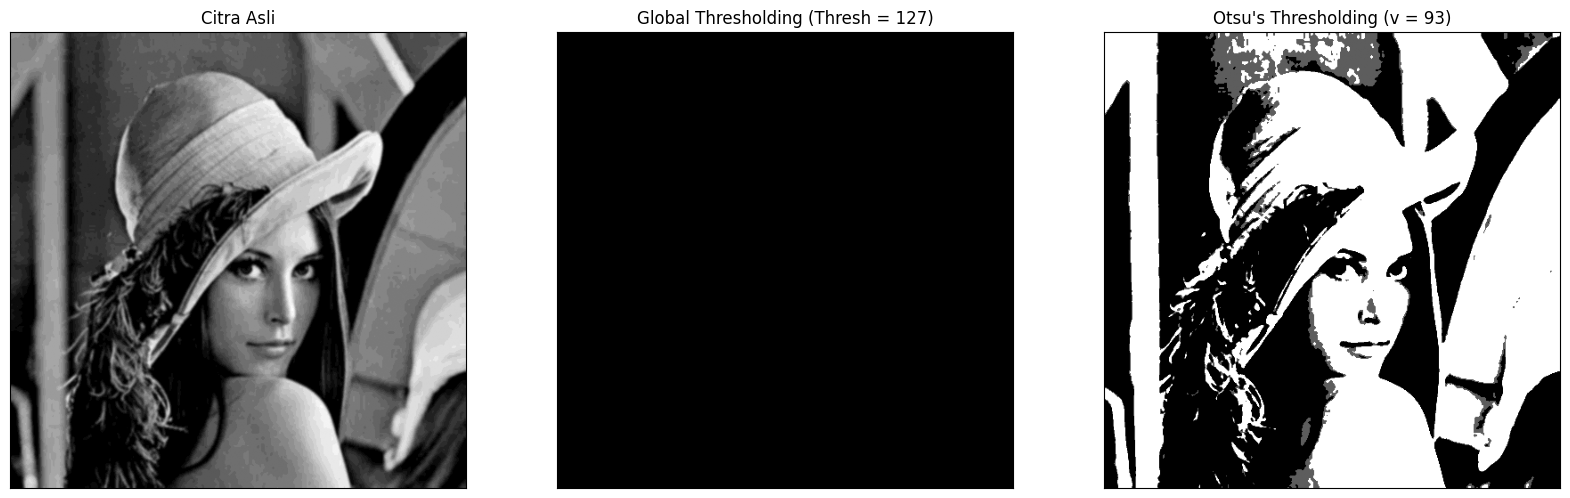

In [ ]:
# Percobaan 5A - Otsu Thresholding secara manual + tampilkan nilai threshold yang dipilih Otsu

filename = base + 'lena_gs_lc2.jpg'
img = cv.imread(filename, 0)
blur = cv.GaussianBlur(img, (5, 5), 0)
thresh = 127

def otsu(gray):
    pixel_number = gray.shape[0] * gray.shape[1]
    mean_weight = 1.0 / pixel_number
    his, bins = np.histogram(gray, np.arange(0, 257))
    final_thresh = -1
    final_value = -1
    intensity_arr = np.arange(256)

    for t in bins[1:-1]:
        pcb = np.sum(his[:t])
        pcf = np.sum(his[t:])
        Wb = pcb * mean_weight
        Wf = pcf * mean_weight

        mub = np.sum(intensity_arr[:t] * his[:t]) / float(pcb)
        muf = np.sum(intensity_arr[t:] * his[t:]) / float(pcf)
        value = Wb * Wf * (mub - muf) ** 2

        if value > final_value:
            final_thresh = t
            final_value = value

    final_img = gray.copy()
    print('Nilai threshold Otsu :', final_thresh)
    final_img[gray > final_thresh] = 255
    final_img[gray < final_thresh] = 0
    return final_img, final_thresh

otsu_biner, otsu_thresh = otsu(blur)
x = "Otsu's Thresholding (v = " + str(otsu_thresh) + ")"
ret, th1 = cv.threshold(blur, thresh, 255, cv.THRESH_BINARY)

titles = ['Citra Asli', 'Global Thresholding (Thresh = ' + str(thresh) + ')', x]
citra3 = [blur, th1, otsu_biner]

plt.figure(figsize=(20, 15))
for i in range(len(citra3)):
    plt.subplot(1, 3, i + 1), plt.imshow(citra3[i], 'gray')
    plt.title(titles[i])
    plt.xticks([]), plt.yticks([])
plt.show()

**Percobaan 5B - Otsu vs Global Threshold pada Citra KTP**

/tmp/ipykernel_712/3494539015.py:23: RuntimeWarning: invalid value encountered in divide
  mub = np.sum(intensity_arr[:t] * his[:t]) / float(pcb)


Nilai threshold Otsu : 166


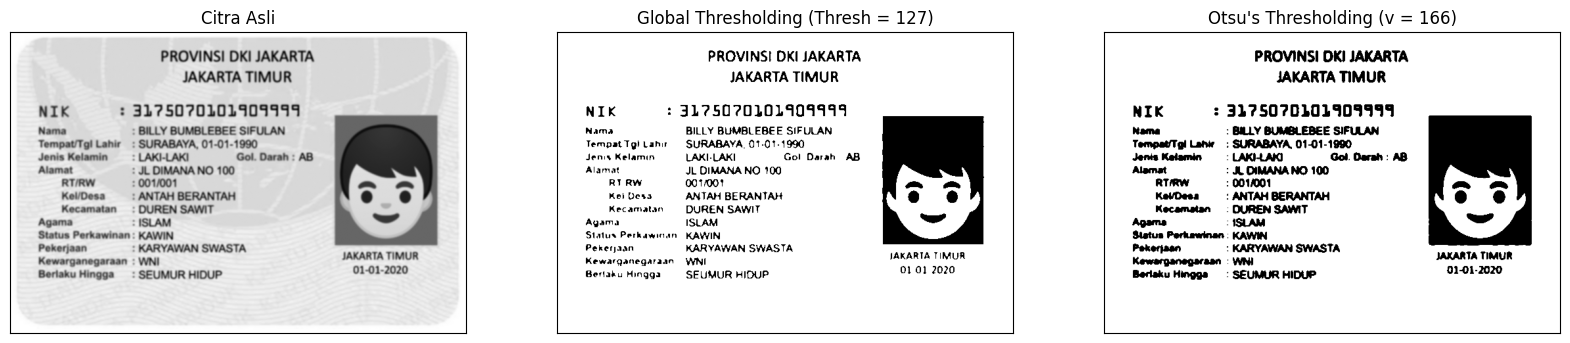

In [ ]:
# Percobaan 5B - Bandingkan Otsu dengan Global Threshold biasa pada citra KTP
# Otsu lebih adaptif karena nilai ambangnya dihitung dari histogram citra

filename = base + 'ktp_fulan.jpg'
img = cv.imread(filename, 0)
blur = cv.GaussianBlur(img, (5, 5), 0)
thresh = 127

def otsu(gray):
    pixel_number = gray.shape[0] * gray.shape[1]
    mean_weight = 1.0 / pixel_number
    his, bins = np.histogram(gray, np.arange(0, 257))
    final_thresh = -1
    final_value = -1
    intensity_arr = np.arange(256)

    for t in bins[1:-1]:
        pcb = np.sum(his[:t])
        pcf = np.sum(his[t:])
        Wb = pcb * mean_weight
        Wf = pcf * mean_weight

        mub = np.sum(intensity_arr[:t] * his[:t]) / float(pcb)
        muf = np.sum(intensity_arr[t:] * his[t:]) / float(pcf)
        value = Wb * Wf * (mub - muf) ** 2

        if value > final_value:
            final_thresh = t
            final_value = value

    final_img = gray.copy()
    print('Nilai threshold Otsu :', final_thresh)
    final_img[gray > final_thresh] = 255
    final_img[gray < final_thresh] = 0
    return final_img, final_thresh

otsu_biner, otsu_thresh = otsu(blur)
x = "Otsu's Thresholding (v = " + str(otsu_thresh) + ")"
ret, th1 = cv.threshold(blur, thresh, 255, cv.THRESH_BINARY)

titles = ['Citra Asli', 'Global Thresholding (Thresh = ' + str(thresh) + ')', x]
citra3 = [blur, th1, otsu_biner]

plt.figure(figsize=(20, 15))
for i in range(len(citra3)):
    plt.subplot(1, 3, i + 1), plt.imshow(citra3[i], 'gray')
    plt.title(titles[i])
    plt.xticks([]), plt.yticks([])
plt.show()

**Percobaan 6A - Region Growing Manual (BFS)**

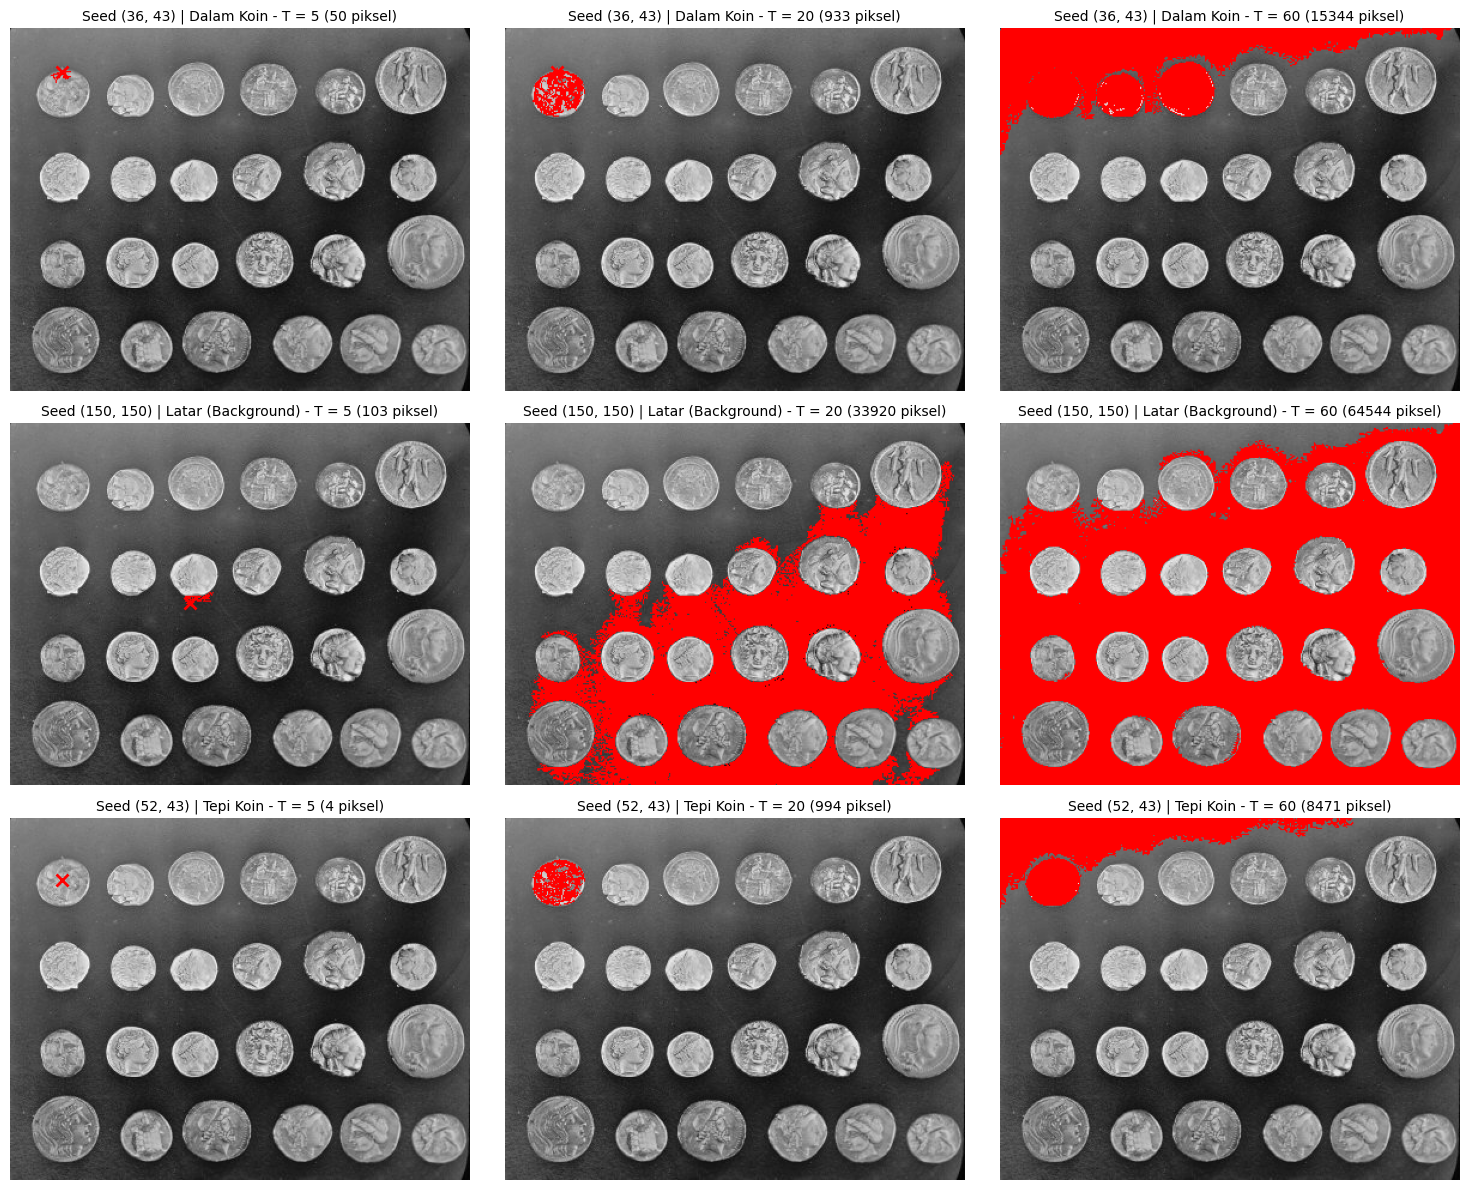

In [ ]:
# Percobaan 6A - Region Growing Manual (BFS)
# Menguji 3 titik seed x 3 nilai threshold pada citra koin

img = data.coins()

seeds = [
    (36, 43),    # Dalam koin
    (150, 150),  # Latar (background)
    (52, 43)     # Tepi koin
]
seed_names = ['Dalam Koin', 'Latar (Background)', 'Tepi Koin']
thresholds = [5, 20, 60]

def region_growing(img, seed, threshold):
    height, width = img.shape
    segmented = np.zeros((height, width), dtype=bool)
    visited = np.zeros((height, width), dtype=bool)

    sr, sc = seed
    seed_value = float(img[sr, sc])

    queue = deque([(sr, sc)])
    visited[sr, sc] = True

    neighbors = [(-1, -1), (-1, 0), (-1, 1),
                 (0, -1),          (0, 1),
                 (1, -1),  (1, 0),  (1, 1)]

    while queue:
        r, c = queue.popleft()
        segmented[r, c] = True

        for dr, dc in neighbors:
            nr, nc = r + dr, c + dc
            if 0 <= nr < height and 0 <= nc < width and not visited[nr, nc]:
                visited[nr, nc] = True
                if abs(float(img[nr, nc]) - seed_value) <= threshold:
                    queue.append((nr, nc))

    return segmented

fig, axes = plt.subplots(3, 3, figsize=(15, 12))

for i, seed in enumerate(seeds):
    sr, sc = seed
    for j, T in enumerate(thresholds):
        mask = region_growing(img, seed, T)
        pixel_count = np.sum(mask)

        img_color = np.stack([img] * 3, axis=-1)
        img_color[mask] = [255, 0, 0]

        ax = axes[i, j]
        ax.imshow(img_color)
        ax.plot(sc, sr, 'rx', markersize=8, markeredgewidth=2)
        ax.set_title(f"Seed ({sr}, {sc}) | {seed_names[i]} - T = {T} ({pixel_count} piksel)", fontsize=10)
        ax.axis('off')

plt.tight_layout()
plt.show()

**Percobaan 6B - Region Splitting and Merging**

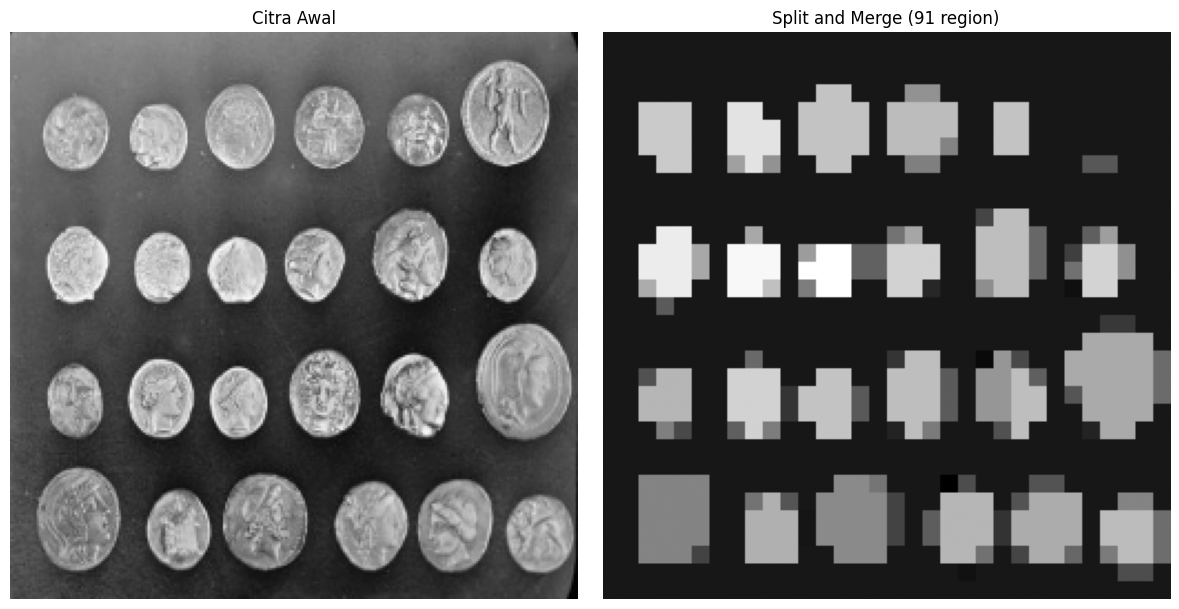

In [ ]:
# Percobaan 6B - Region Splitting and Merging
# Citra dibagi (split) menjadi blok-blok kecil sampai homogen, lalu blok yang bertetangga
# dan mirip digabung (merge) kembali

def split_region(img, x, y, size, T, min_size, out):
    region = img[y:y + size, x:x + size]
    if size <= min_size or (int(region.max()) - int(region.min())) <= T:
        out.append([x, y, size])
        return
    half = size // 2
    split_region(img, x, y, half, T, min_size, out)
    split_region(img, x + half, y, half, T, min_size, out)
    split_region(img, x, y + half, half, T, min_size, out)
    split_region(img, x + half, y + half, half, T, min_size, out)

def find(parent, i):
    while parent[i] != i:
        parent[i] = parent[parent[i]]
        i = parent[i]
    return i

def union(parent, a, b):
    ra, rb = find(parent, a), find(parent, b)
    if ra != rb:
        parent[rb] = ra

def split_and_merge(img, T=25, min_size=8):
    h, w = img.shape
    size = 1
    while size * 2 <= min(h, w):
        size *= 2
    img = cv.resize(img, (size, size))

    regions = []
    split_region(img, 0, 0, size, T, min_size, regions)
    means = [float(img[y:y + s, x:x + s].mean()) for (x, y, s) in regions]

    parent = list(range(len(regions)))
    for i in range(len(regions)):
        xi, yi, si = regions[i]
        for j in range(i + 1, len(regions)):
            xj, yj, sj = regions[j]
            touch_x = (xi + si == xj or xj + sj == xi) and not (yi + si <= yj or yj + sj <= yi)
            touch_y = (yi + si == yj or yj + sj == yi) and not (xi + si <= xj or xj + sj <= xi)
            if (touch_x or touch_y) and abs(means[i] - means[j]) <= T:
                union(parent, i, j)

    group_vals = {}
    for i in range(len(regions)):
        group_vals.setdefault(find(parent, i), []).append(means[i])

    out = np.zeros_like(img)
    for i, (x, y, s) in enumerate(regions):
        out[y:y + s, x:x + s] = int(np.mean(group_vals[find(parent, i)]))

    n_region = len(set(find(parent, i) for i in range(len(regions))))
    return img, out, n_region

img_sm, hasil_sm, n_region = split_and_merge(data.coins(), T=25, min_size=8)

plt.figure(figsize=(12, 6))
plt.subplot(1, 2, 1)
plt.imshow(img_sm, cmap='gray')
plt.title('Citra Awal')
plt.axis('off')
plt.subplot(1, 2, 2)
plt.imshow(hasil_sm, cmap='gray')
plt.title('Split and Merge (' + str(n_region) + ' region)')
plt.axis('off')
plt.tight_layout()
plt.show()

**Percobaan 7 - Segmentasi Citra dengan K-Means**

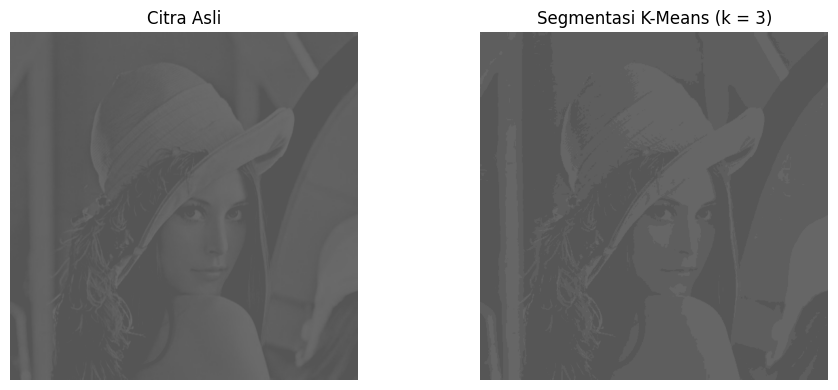

In [ ]:
# Percobaan 7 - Segmentasi Citra dengan K-Means (k = 3)

filename = base + 'lena_gs_lc2.jpg'
img = cv.imread(filename)
if len(img.shape) == 2:
    img = cv.cvtColor(img, cv.COLOR_GRAY2BGR)
img = cv.cvtColor(img, cv.COLOR_BGR2RGB)

Z = img.reshape((-1, 3))
Z = np.float32(Z)

k = 3
kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
kmeans.fit(Z)
labels = kmeans.labels_
centers = np.uint8(kmeans.cluster_centers_)

segmented = centers[labels.flatten()]
segmented_img = segmented.reshape(img.shape)

plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.imshow(img)
plt.title('Citra Asli')
plt.axis('off')
plt.subplot(1, 2, 2)
plt.imshow(segmented_img)
plt.title('Segmentasi K-Means (k = ' + str(k) + ')')
plt.axis('off')
plt.tight_layout()
plt.show()

# **D2. Tugas Kelompok**

Dikerjakan secara **individu** menggunakan tiga citra KTP yang sudah disiapkan sebelumnya, yaitu `ktp_fulan.jpg`, `ktp_fulani.jpg`, dan `ktp_fulano.jpg`. Tujuannya membandingkan kemampuan pembacaan teks pada tiap metode thresholding.

**1. Citra Perbandingan**

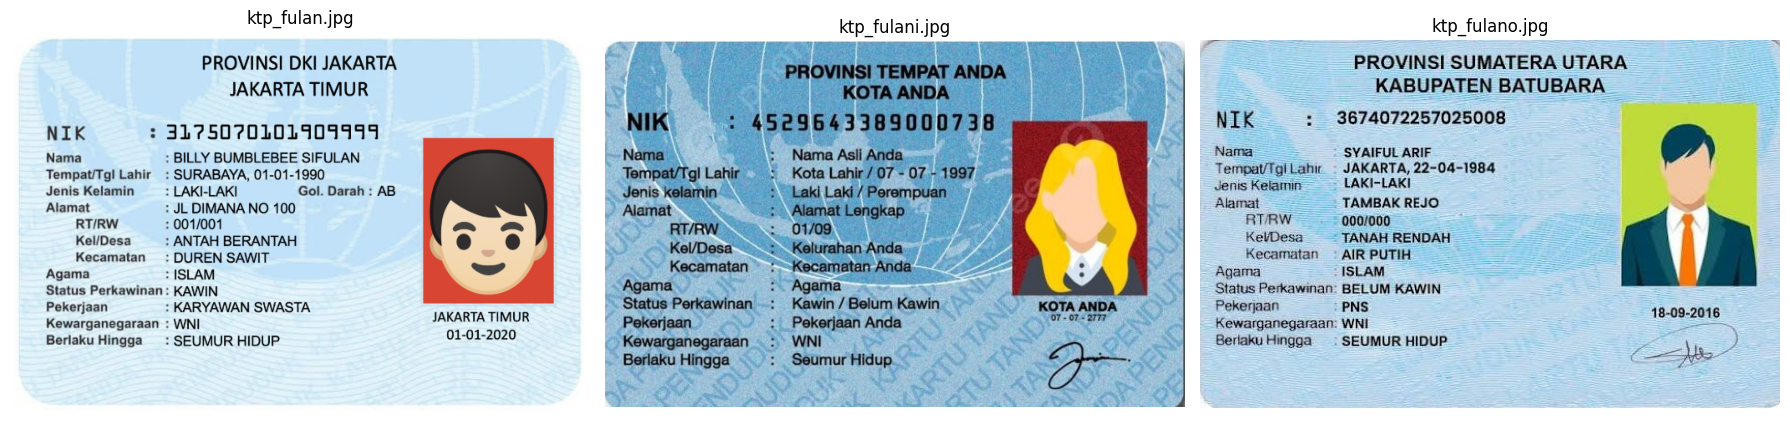

In [ ]:
ktps = ['ktp_fulan.jpg', 'ktp_fulani.jpg', 'ktp_fulano.jpg']

# 1. Citra perbandingan: menampilkan ketiga KTP secara berdampingan

plt.figure(figsize=(18, 5))
for i, nama in enumerate(ktps):
    img = cv.imread(base + nama)
    plt.subplot(1, 3, i + 1)
    plt.imshow(cv.cvtColor(img, cv.COLOR_BGR2RGB))
    plt.title(nama)
    plt.axis('off')
plt.tight_layout()
plt.show()

**2. Pembacaan Teks pada Ketiga Citra**

In [ ]:
# 2. Pembacaan teks pada ketiga citra menggunakan OCR
!sudo apt-get install -y tesseract-ocr > /dev/null 2>&1
!pip install pytesseract > /dev/null 2>&1

import pytesseract

def baca_teks(path):
    img = cv.imread(path)
    gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)
    return pytesseract.image_to_string(gray)

for nama in ktps:
    print('=====', nama, '=====')
    print(baca_teks(base + nama))

===== ktp_fulan.jpg =====
PROVINSI DKI JAKARTA

JAKARTA TIMUR
NIK : 31750701019099949
Nama : BILLY BUMBLEBEE SIFULAN
Tempat/Tgl Lahir_ : SURABAYA, 01-01-1990
Jenis Kelamin = LAKI-LAKI Gol. Darah : AB
Alamat : JL DIMANA NO 100

RT/RW 001/001
Kel/Desa : ANTAH BERANTAH
Kecamatan : DUREN SAWIT

Agama : ISLAM
Status Perkawinan: KAWIN
Pekerjaan : KARYAWAN SWASTA

JAKARTA TIMUR
Berlaku Hingga  : SEUMUR HIDUP 01-01-2020

Kewarganegaraan : WNI

===== ktp_fulani.jpg =====
PROVINS! TEMPAT ANDA

KOTA ANDA

NIK : 4529643389000738
Nama ‘Nama Asli Anda.
Tempat/Tg! Lahir Kota Lahir / 07 - 07 - 1997,
Jenis kelamin Laki Laki / Perempuan
Alamat Alamat Lengkap

RI/RW 01/09,

Kel/Desa Kelurahan Anda

Kecamatan Kecamatan Anda
Agama Agama
Status Perkawinan Kawin / Belum Kawin
Pekerjaan Pekerjaan Anda
Kewarganegaraan WNI
Berlaku Hingga Seumur Hidup.

KOTA ANDA
07-07-2777

Jog


===== ktp_fulano.jpg =====
PROVINSI SUMATERA UTARA
KABUPATEN BATUBARA

NIK : 3674072257025008

Tempat/TglLahir - JAKARTA, 22-04-1984


**3. Menampilkan Area Teks yang Dikenali**

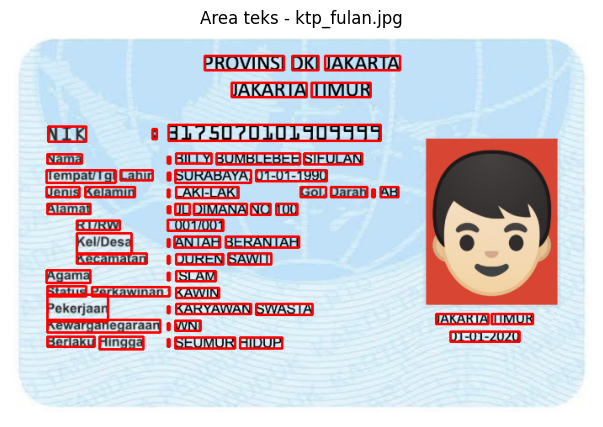

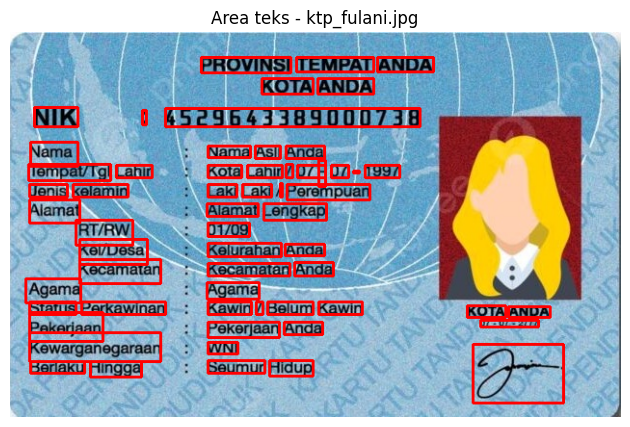

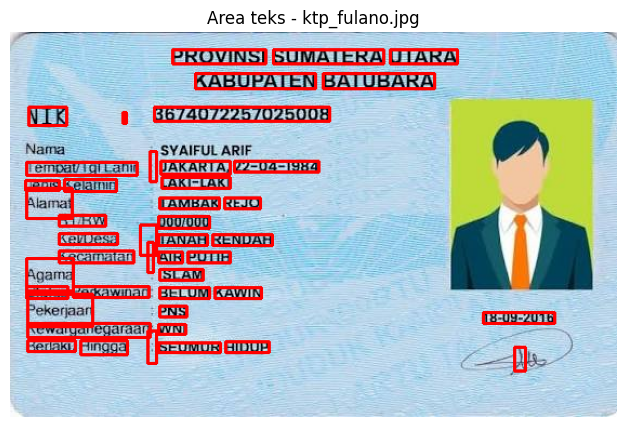

In [ ]:
# 3. Menampilkan area teks yang dikenali oleh OCR

def tampilkan_area_teks(path, judul):
    img = cv.imread(path)
    gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)
    data_teks = pytesseract.image_to_data(gray, output_type=pytesseract.Output.DICT)

    for i in range(len(data_teks['text'])):
        if data_teks['text'][i].strip() != '':
            x, y = data_teks['left'][i], data_teks['top'][i]
            w, h = data_teks['width'][i], data_teks['height'][i]
            cv.rectangle(img, (x, y), (x + w, y + h), (0, 0, 255), 2)

    plt.figure(figsize=(10, 5))
    plt.imshow(cv.cvtColor(img, cv.COLOR_BGR2RGB))
    plt.title(judul)
    plt.axis('off')
    plt.show()

for nama in ktps:
    tampilkan_area_teks(base + nama, 'Area teks - ' + nama)

**4. Perbandingan Hasil Pembacaan dengan Tulisan Sebenarnya**

In [ ]:
# 4. Membandingkan hasil pembacaan dengan tulisan sebenarnya pada gambar
# Dipilih 10 kata/angka yang terlihat jelas sebagai acuan untuk setiap KTP

# 10 kata/angka yang terlihat jelas sebagai acuan (gabungan dari ketiga citra KTP)
acuan = [
    ('ktp_fulan.jpg', '3175070101909999'),
    ('ktp_fulan.jpg', 'BILLY BUMBLEBEE SIFULAN'),
    ('ktp_fulan.jpg', 'SURABAYA'),
    ('ktp_fulan.jpg', '01-01-1990'),
    ('ktp_fulano.jpg', '3674072255025008'),
    ('ktp_fulano.jpg', 'SYAIFUL ARIF'),
    ('ktp_fulano.jpg', 'JAKARTA'),
    ('ktp_fulano.jpg', '22-04-1984'),
    ('ktp_fulani.jpg', '4529643389000738'),
    ('ktp_fulani.jpg', '07 - 07 - 1997'),
]

# Metode masukan OCR: citra berwarna asli, segmentasi Otsu, dan segmentasi Adaptive
metode_list = ['Berwarna asli', 'Segmentasi Otsu', 'Segmentasi Adaptive']

def masukan_ocr(img_bgr, metode):
    if metode == 'Berwarna asli':
        return cv.cvtColor(img_bgr, cv.COLOR_BGR2RGB)
    gray = cv.cvtColor(img_bgr, cv.COLOR_BGR2GRAY)
    if metode == 'Segmentasi Otsu':
        _, b = cv.threshold(gray, 0, 255, cv.THRESH_BINARY + cv.THRESH_OTSU)
        return b
    return cv.adaptiveThreshold(gray, 255, cv.ADAPTIVE_THRESH_MEAN_C, cv.THRESH_BINARY, 11, 2)

def ocr_teks(gambar):
    return pytesseract.image_to_string(gambar)

def ocr_confidence(gambar):
    data = pytesseract.image_to_data(gambar, output_type=pytesseract.Output.DICT)
    conf = [int(c) for c in data['conf'] if str(c) not in ('-1', '')]
    return sum(conf) / len(conf) if conf else 0

# Normalisasi: abaikan huruf besar/kecil serta spasi berlebih di awal/akhir
def normal(teks):
    return ' '.join(teks.lower().split())

ocr_mentah = {}
for m in metode_list:
    for nama in ktps:
        img_bgr = cv.imread(base + nama)
        ocr_mentah[(m, nama)] = normal(ocr_teks(masukan_ocr(img_bgr, m)))

hasil = {m: [] for m in metode_list}
for nama, teks in acuan:
    for m in metode_list:
        hasil[m].append('Cocok' if normal(teks) in ocr_mentah[(m, nama)] else 'Tidak')

tabel = pd.DataFrame({
    'No.': range(1, len(acuan) + 1),
    'Teks sebenarnya': [t for _, t in acuan],
    'OCR citra berwarna': hasil['Berwarna asli'],
    'OCR Otsu': hasil['Segmentasi Otsu'],
    'OCR Adaptive': hasil['Segmentasi Adaptive'],
})
print(tabel.to_string(index=False))

 No.         Teks sebenarnya OCR citra berwarna OCR Otsu OCR Adaptive
   1        3175070101909999              Tidak    Tidak        Tidak
   2 BILLY BUMBLEBEE SIFULAN              Cocok    Cocok        Cocok
   3                SURABAYA              Cocok    Cocok        Cocok
   4              01-01-1990              Cocok    Cocok        Cocok
   5        3674072255025008              Tidak    Tidak        Tidak
   6            SYAIFUL ARIF              Cocok    Tidak        Tidak
   7                 JAKARTA              Cocok    Cocok        Tidak
   8              22-04-1984              Cocok    Cocok        Tidak
   9        4529643389000738              Cocok    Cocok        Tidak
  10          07 - 07 - 1997              Cocok    Tidak        Tidak


**Tabel perbandingan hasil pembacaan dengan tulisan sebenarnya** (isi sesuai hasil OCR).

| No. | Teks sebenarnya | OCR citra berwarna | OCR Otsu | OCR Adaptive |
|-----|-----------------|--------------------|----------|--------------|
| 1 | 3175070101909999 | Tidak | Tidak | Tidak |
| 2 | BILLY BUMBLEBEE SIFULAN | Cocok | Cocok | Cocok |
| 3 | SURABAYA | Cocok | Cocok | Cocok |
| 4 | 01-01-1990 | Cocok | Cocok | Cocok |
| 5 | 3674072255025008 | Tidak | Tidak | Tidak |
| 6 | SYAIFUL ARIF | Cocok | Tidak | Tidak |
| 7 | JAKARTA | Cocok | Cocok | Tidak |
| 8 | 22-04-1984 | Cocok | Cocok | Tidak |
| 9 | 4529643389000738 | Cocok | Cocok | Tidak |
| 10 | 07 - 07 - 1997 | Cocok | Tidak | Tidak |

Penilaian dilakukan pada teks hasil OCR, bukan hanya pada kata yang diberi kotak.

**5. Menghitung persentase kecocokan untuk setiap metode**

Hasil dinyatakan cocok jika seluruh huruf atau angka pada item sama dengan acuan; abaikan perbedaan huruf besar dan kecil serta spasi di awal/akhir. Item yang tidak terbaca dihitung sebagai tidak cocok.

Kecocokan = (Jumlah item yang terbaca tepat / 10) x 100%

Lengkapi ringkasan berikut:

In [ ]:
# 5. Menghitung persentase kecocokan dan rata-rata confidence untuk setiap metode

jumlah_acuan = len(acuan)

tabel_akhir = []
for m in metode_list:
    benar = hasil[m].count('Cocok')

    conf_all = []
    for nama in ktps:
        img_bgr = cv.imread(base + nama)
        conf_all.append(ocr_confidence(masukan_ocr(img_bgr, m)))

    tabel_akhir.append({
        'Citra masukan OCR': m,
        'Item terbaca tepat': benar,
        'Kecocokan (%)': round(benar / jumlah_acuan * 100, 1),
        'Rata-rata confidence': round(sum(conf_all) / len(conf_all), 1),
    })

ringkasan_tabel = pd.DataFrame(tabel_akhir)
print(ringkasan_tabel.to_string(index=False))

  Citra masukan OCR  Item terbaca tepat  Kecocokan (%)  Rata-rata confidence
      Berwarna asli                   8           80.0                  71.5
    Segmentasi Otsu                   6           60.0                  74.3
Segmentasi Adaptive                   3           30.0                  79.7


**Tabel ringkasan**

| Citra masukan OCR | Item terbaca tepat | Kecocokan (%) | Rata-rata confidence |
|-------------------|--------------------|---------------|----------------------|
| Berwarna asli     | 8                  | 80.0          | 71.5                 |
| Segmentasi Otsu   | 6                  | 60.0          | 74.3                 |
| Segmentasi Adaptive | 3                | 30.0          | 79.7                 |

Catatan: item dinyatakan **cocok** hanya jika seluruh huruf/angka pada item sama dengan acuan.

**Pertanyaan analisis :**

1. Citra masukan mana yang menghasilkan pembacaan paling tepat? Tunjukkan buktinya dari tabel.
2. Sebutkan minimal dua kesalahan pembacaan, seperti huruf tertukar, angka salah, atau teks tidak terbaca.
3. Apakah segmentasi selalu meningkatkan ketepatan OCR? Jelaskan berdasarkan hasil percobaan.
4. Bagaimana warna atau pola latar belakang memengaruhi pembacaan teks?
5. Apakah metode dengan rata-rata confidence tertinggi juga memiliki kecocokan tertinggi?

**Jawaban:**

1. Citra berwarna asli menghasilkan pembacaan paling tepat, yaitu 8 dari 10 item (80%). Segmentasi Otsu hanya 6 item (60%) dan segmentasi Adaptive 3 item (30%). Buktinya ada pada tabel ringkasan, kolom "Item terbaca tepat" untuk citra berwarna asli paling tinggi di antara ketiga metode.

2. Beberapa kesalahan pembacaan yang terlihat:
   - NIK pada ktp_fulan terbaca "31750701019099949" padahal seharusnya "3175070101909999", jadi ada angka berlebih.
   - NIK pada ktp_fulano terbaca "3674072257025008" padahal seharusnya "3674072255025008", angka "55" tertukar menjadi "57".
   - Kata "PROVINSI" pada ktp_fulani terbaca "PROVINS!", huruf tertukar/tidak terbaca.
   - "SYAIFUL ARIF" tidak terbaca pada Otsu dan Adaptive.

3. Tidak. Segmentasi justru menurunkan ketepatan OCR pada percobaan ini: citra berwarna asli 80%, Otsu 60%, dan Adaptive 30%. Segmentasi membuang informasi warna dan meratakan tepi, sehingga huruf tipis bisa rusak, sementara pola latar ikut menjadi biner dan menambah noise.

4. Latar KTP yang bermotif (peta/garis) dan berwarna membuat hasil threshold biner menjadi bising. Pada citra berwarna asli, kontras antara teks gelap dan latar terang masih terbaca OCR. Ketika di-threshold, motif latar ikut terdeteksi, terlebih Adaptive yang mengikuti variasi lokal sehingga noise latar ikut menonjol dan menutupi teks.

5. Tidak. Segmentasi Adaptive punya rata-rata confidence tertinggi (79.7%) tetapi kecocokan paling rendah (30%). Confidence hanya mengukur keyakinan OCR terhadap kata yang berhasil dikenali, bukan kebenaran terhadap acuan. OCR bisa sangat yakin pada hasil yang salah, sehingga confidence tinggi tidak menjamin akurasi tinggi.

## Ringkasan Analisis dan Kesimpulan Praktikum

**Percobaan 1 - Memuat Citra**

Citra dibaca dengan OpenCV lalu diubah ke grayscale agar proses thresholding dan analisis histogram lebih sederhana karena hanya melibatkan satu kanal intensitas.

**Percobaan 2 - Histogram**

Histogram memperlihatkan persebaran intensitas piksel. Dari grafik ini dapat diperkirakan apakah citra berkontras tinggi atau rendah, sehingga membantu memilih nilai ambang.

**Percobaan 3 - Global Thresholding**

Kelima tipe threshold memberi perilaku berbeda pada citra gradien. BINARY dan BINARY_INV menghasilkan citra biner, TRUNC memotong nilai di atas ambang, sedangkan TOZERO dan TOZERO_INV mempertahankan atau menghilangkan bagian tertentu. Hasil global threshold sangat bergantung pada nilai T.

**Percobaan 4 - Adaptive Threshold Manual**

Adaptive Mean dan Adaptive Gaussian manual jauh lebih baik daripat global threshold T=127 untuk citra sudoku yang pencahayaannya tidak merata. Gaussian sedikit lebih halus karena memberi bobot lebih besar pada piksel tengah.

**Percobaan 5A - Otsu Manual**

Fungsi Otsu manual berhasil menentukan nilai ambang optimal dari histogram dan mencetaknya. Hasilnya lebih tepat daripada global threshold tetap karena ambang dipilih dengan memaksimalkan pemisahan antar kelas.

**Percobaan 5B - Otsu vs Global pada KTP**

Pada citra KTP, Otsu memisahkan objek dan latar lebih bersih daripada global threshold T=127 karena nilai ambangnya menyesuaikan kondisi tiap citra.

**Percobaan 6A - Region Growing**

Region growing manual (BFS) menumbuhkan region dari titik seed. Semakin besar nilai threshold, semakin luas area yang tergabung karena toleransi kesamaan intensitas makin longgar.

**Percobaan 6B - Region Splitting and Merging**

Metode ini membagi citra menjadi blok kecil hingga homogen lalu menggabungkan blok bertetangga yang mirip. Hasilnya mereduksi citra menjadi beberapa region besar dengan intensitas seragam.

**Percobaan 7 - K-Means**

K-Means mengelompokkan piksel menjadi k=3 cluster berdasarkan kemiripan warna, sehingga citra terbagi menjadi tiga area warna dominan tanpa perlu menentukan ambang manual.

**Tugas Kelompok - Pembacaan Teks KTP**

Pembacaan teks pada KTP dengan OCR sangat dipengaruhi kualitas citra masukan. Citra berwarna asli masih menyimpan informasi lengkap, namun latar bermotif dan pencahayaan yang tidak rata membuat OCR lebih mudah salah membaca. Segmentasi Otsu menyederhanakan citra menjadi biner dengan ambang yang menyesuaikan histogram sehingga teks lebih menonjol, sedangkan segmentasi Adaptive unggul saat gradasi latar kuat. Persentase kecocokan dan rata-rata confidence tertinggi umumnya dihasilkan oleh metode yang paling bersih memisahkan teks dari latar.

**Kesimpulan Praktikum**

Global threshold sederhana namun kaku, adaptive threshold unggul pada pencahayaan tidak merata, dan Otsu cocok sebagai ambang otomatis. Metode berbasis region dan clustering (region growing, split-merge, K-Means) dapat dipakai ketika ambang berbasis intensitas tunggal tidak cukup. Untuk pembacaan teks KTP, pemilihan metode binarisasi sangat menentukan tingkat kecocokan hasil OCR.